<a href="https://colab.research.google.com/github/arraks1307/dungeon-roguelike/blob/main/homework/lesson-14/solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Урок 14. Регрессия цены дома: рабочий ноутбук

Пишите код в уже созданных Code-ячейках. Добавлять новые ячейки не требуется. Блок **? ВЫВОДЫ** — место для собственного объяснения результатов словами. Перед сдачей перезапустите ядро, выполните все ячейки сверху вниз и сохраните выводы.

Сдайте один файл **`solution.ipynb`** с кодом, таблицами, графиками и ответами. Отдельные картинки, CSV и текстовый отчёт не требуются. Дедлайн сообщает преподаватель.

На занятии самостоятельной практики нет. Все задания ниже — **домашняя работа**. Рядом нужен `AmesHousing_lesson.csv`: учебная версия данных о домах с пропусками, неверными значениями и повторениями. Читаем именно её, не очищенный файл из показа.

Источник темы — [Ames Housing на Kaggle](https://www.kaggle.com/datasets/shashanknecrothapa/ames-housing-dataset). Исходные единицы: квадратные футы и доллары. В работе переводим площади в м², цену — в тысячи долларов.

## 🟨❗ Краткая справка к домашней работе

| Библиотека / инструмент | Для чего нужен |
|---|---|
| Pandas (`pd`) | Прочитать CSV, выбрать копию, переименовать, проверить и отфильтровать строки |
| NumPy (`np`) | Вычислить корень для RMSE и массив постоянных прогнозов |
| Matplotlib (`plt`) | Нарисовать сравнение ошибок |
| scikit-learn (`sklearn`) | Подготовить входы, обучить модель и измерить ошибки |
| `train_test_split` | Создать две непересекающиеся части строк |
| `SimpleImputer(strategy='mean')` | На fit запомнить средние обучения; на transform заполнить пропуски готовыми средними |
| `LinearRegression` | На fit подобрать коэффициенты числовой формулы по X и известным y; на predict применить эту формулу |
| `mean_absolute_error` | MAE: среднее абсолютных промахов |
| `mean_squared_error` | Среднее квадратов промахов; RMSE получим через `np.sqrt(...)` |

MAE и RMSE считаем **на отложенных домах** в тысячах долларов. Для ошибок +10, −20, +30 MAE = (10+20+30)/3 = 20; RMSE = √((100+400+900)/3) ≈ 21,60. RMSE сильнее реагирует на крупные промахи. Это не стандартное отклонение цен вокруг их среднего.

Если scikit-learn не установлен, выполните `%pip install scikit-learn`, затем перезапустите ядро. Импорт библиотеки называется `sklearn`.

**Что делает следующая ячейка.** Подключает библиотеки таблиц, вычислений, графиков и инструменты подготовки и регрессии. Никакие данные ещё не изменены.

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

## 4. Какие столбцы оставим для примера?

Для первой модели понадобится только площадь. Затем постепенно добавим другие понятные характеристики. Номер сохраняем для поиска повторов, цену — как известный ответ; **они не входят в десять входных признаков**.

| Поле CSV | Понятное название | Что содержится | Единица после перевода |
|---|---|---|---|
| `Order` | Номер | Номер записи | — |
| `Gr Liv Area` | Площадь | Надземная жилая площадь дома | м² |
| `Overall Qual` | Качество | Материалы и отделка | оценка 1–10 |
| `Year Built` | Год постройки | Когда дом построен | год |
| `Total Bsmt SF` | Подвал | Общая площадь подвала | м² |
| `Garage Area` | Гараж | Площадь гаража | м² |
| `Lot Area` | Участок | Площадь земельного участка | м² |
| `Full Bath` | Ванные | Число полных ванных над землёй | штук |
| `Bedroom AbvGr` | Спальни | Число спален над землёй | штук |
| `Fireplaces` | Камины | Число каминов | штук |
| `Lot Frontage` | Граница | Длина участка вдоль улицы | м |
| `SalePrice` | Цена | Известная цена продажи | тыс. $ |

У нулевой площади гаража есть смысл: гаража нет. Пропуск площади гаража означает другое: значение не записано.

## 🏠 Д1. Прочитаем, осмотрим и подготовим рабочие поля

Прочитайте весь CSV в `raw_data`. Выведите размеры, список полей, первые строки и объясните словами, что описывает один дом. По таблице выше выберите 12 полей в отдельную `.copy()` с именем `houses`.

Создайте словарь `column_names` «исходное название → русское» и переименуйте через `rename(columns=column_names)`. Переведите четыре площади `Площадь, Подвал, Гараж, Участок` умножением на `0.09290304`; длину `Граница` — на `0.3048`; цену — делением на `1000`. Валюту не меняем.

Подготовьте `target='Цена'` и список `features_ten` из десяти характеристик в порядке таблицы. Выведите пропуски каждого поля и примеры с неизвестной границей. Начните журнал `cleaning_log` со словарём `{'Этап':'Исходная рабочая таблица','Строк':len(houses)}`.

`copy` создаёт рабочую копию; `rename` применяет словарь к заголовкам, не меняя значения. `isna().sum()` считает неизвестные значения; они не равны нулю.

**Что делает следующая ячейка.** Ваш код читает полную таблицу, выбирает поля, переименовывает и меняет единицы. Число строк на этом шаге не уменьшается.

In [25]:
# Напишите решение здесь.
raw_data = pd.read_csv('AmesHousing_lesson.csv')

print('Размеры исходной таблицы:', raw_data.shape)
print('\nСписок полей:')
print(list(raw_data.columns))
print('\nПервые строки:')
display(raw_data.head())

# Выбор 12 полей и рабочая копия
fields = ['Order', 'Gr Liv Area', 'Overall Qual', 'Year Built', 'Total Bsmt SF',
          'Garage Area', 'Lot Area', 'Full Bath', 'Bedroom AbvGr', 'Fireplaces',
          'Lot Frontage', 'SalePrice']

houses = raw_data[fields].copy()

column_names = {
    'Order': 'Номер',
    'Gr Liv Area': 'Площадь',
    'Overall Qual': 'Качество',
    'Year Built': 'Год постройки',
    'Total Bsmt SF': 'Подвал',
    'Garage Area': 'Гараж',
    'Lot Area': 'Участок',
    'Full Bath': 'Ванные',
    'Bedroom AbvGr': 'Спальни',
    'Fireplaces': 'Камины',
    'Lot Frontage': 'Граница',
    'SalePrice': 'Цена'
}

houses = houses.rename(columns=column_names)

# Перевод единиц
houses['Площадь'] = houses['Площадь'] * 0.09290304
houses['Подвал']  = houses['Подвал']  * 0.09290304
houses['Гараж']   = houses['Гараж']   * 0.09290304
houses['Участок'] = houses['Участок'] * 0.09290304
houses['Граница'] = houses['Граница'] * 0.3048
houses['Цена']    = houses['Цена']    / 1000

target = 'Цена'
features_ten = ['Площадь', 'Качество', 'Год постройки', 'Подвал', 'Гараж',
                'Участок', 'Ванные', 'Спальни', 'Камины', 'Граница']

print('Пропуски по полям:')
print(houses.isna().sum())
print('\nПримеры строк с неизвестной границей:')
display(houses[houses['Граница'].isna()].head())

cleaning_log = [{'Этап': 'Исходная рабочая таблица', 'Строк': len(houses)}]
print('\nЖурнал:', cleaning_log)

Размеры исходной таблицы: (2969, 82)

Список полей:
['Order', 'PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air', 'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt', 'Garage Finish', 'Garage Cars', 'Garage Area', 'Gar

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000.0
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000.0
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000.0
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000.0
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900.0


Пропуски по полям:
Номер              0
Площадь           43
Качество          34
Год постройки      0
Подвал             1
Гараж              1
Участок            0
Ванные             0
Спальни            0
Камины             0
Граница          493
Цена              41
dtype: int64

Примеры строк с неизвестной границей:


,Номер,Площадь,Качество,Год постройки,Подвал,Гараж,Участок,Ванные,Спальни,Камины,Граница,Цена
11,12,110.275908,6.0,1992,108.510751,39.019277,741.366259,2,3.0,0,NaN,185.0
14,15,139.540366,8.0,1985,138.239724,49.052805,633.598733,1,1.0,0,NaN,212.0
22,23,155.519689,7.0,2000,75.623075,61.594716,696.772800,2,3.0,0,NaN,216.0
23,24,93.274652,6.0,1970,93.274652,44.593459,1044.323073,1,2.0,1,NaN,149.0
24,25,100.149477,5.0,1971,100.149477,46.451520,1164.725412,1,3.0,1,NaN,149.9



Журнал: [{'Этап': 'Исходная рабочая таблица', 'Строк': 2969}]


### ❓ ? ВЫВОДЫ

Что означает одна строка? Сколько столбцов оставили и почему цена не входит в десять признаков? В каких единицах теперь цена и площадь?

**Мой ответ:**

Одна строка — это один проданный дом с его характеристиками и известной ценой продажи. Мы оставили 12 столбцов: 10 входных признаков, служебный номер (Номер) и целевую переменную (Цена). Цена не входит в десять признаков, потому что она — то, что модель должна предсказывать; если подать её на вход, это будет «подглядывание» в ответ. После перевода цена измеряется в тысячах долларов, а площади (Площадь, Подвал, Гараж, Участок) — в квадратных метрах; длина границы — в метрах.

## 🏠 Д2. Покажем повторы, затем решим, что убрать

1. Покажите полные дубликаты через `duplicated(keep=False)` **до удаления**; посчитайте лишние копии `duplicated().sum()`. Удалите лишнее через `drop_duplicates`, покажите новый размер и повторную проверку. Добавьте этап в журнал.
2. Найдите кандидатов на совпадение по `subset=['Площадь','Год постройки','Качество']`. Покажите их вместе с номером и ценой. Автоматически не удаляйте их: похожие дома могут быть разными.
3. После удаления полных копий найдите повторяющиеся номера через `duplicated(subset=['Номер'],keep=False)`. Покажите несколько пар и все записи первого найденного номера: `.iloc[0]` берёт первое значение, фильтр равенства показывает его записи.
4. Отложите все версии конфликтующих номеров в `houses_conflicts`, исключите их из рабочей `houses`. Покажите, сколько строк отложено, сколько осталось, и убедитесь, что номера больше не повторяются. Запишите этап журнала.

При фильтрации `~mask` означает «строки, где условие не выполнено». Не выбирайте «правильную» цену конфликтующей записи наугад.

**Что делает следующая ячейка.** Ваш код сначала показывает найденные строки, затем удаляет лишние полные копии и откладывает конфликты. Он не удаляет разные дома только из-за похожих характеристик.

In [26]:
# Напишите решение здесь.
# 1. Полные дубликаты
dup_mask = houses.duplicated(keep=False)
print('Строк, участвующих в дубликатах:', dup_mask.sum())
display(houses[dup_mask].head(10))
print('Лишних копий:', houses.duplicated().sum())

before = len(houses)
houses = houses.drop_duplicates().reset_index(drop=True)
print('Размер до:', before, 'после:', len(houses))
print('Повторная проверка дубликатов:', houses.duplicated().sum())
cleaning_log.append({'Этап': 'Удалены полные дубликаты', 'Строк': len(houses)})

# 2. Кандидаты на совпадение по трём характеристикам
cand = houses[houses.duplicated(subset=['Площадь', 'Год постройки', 'Качество'], keep=False)]
cand_sorted = cand.sort_values(['Площадь', 'Год постройки', 'Качество'])
print('Кандидатов (строк):', len(cand_sorted))
display(cand_sorted[['Номер', 'Площадь', 'Год постройки', 'Качество', 'Цена']].head(20))

# 3. Повторяющиеся номера
num_dup = houses[houses.duplicated(subset=['Номер'], keep=False)]
print('Строк с повторяющимися номерами:', len(num_dup))
display(num_dup.sort_values('Номер')[['Номер', 'Площадь', 'Цена']].head(10))

first_num = num_dup['Номер'].iloc[0]
print('Первый конфликтующий номер:', first_num)
display(houses[houses['Номер'] == first_num])

# 4. Откладываем конфликты
conflict_numbers = num_dup['Номер'].unique()
conflict_mask = houses['Номер'].isin(conflict_numbers)

houses_conflicts = houses[conflict_mask].copy()
houses = houses[~conflict_mask].reset_index(drop=True)

print('Отложено строк:', len(houses_conflicts))
print('Осталось строк:', len(houses))
print('Повторные номера после очистки:', houses.duplicated(subset=['Номер']).sum())
cleaning_log.append({'Этап': 'Отложены конфликтующие номера', 'Строк': len(houses)})

Строк, участвующих в дубликатах: 20


,Номер,Площадь,Качество,Год постройки,Подвал,Гараж,Участок,Ванные,Спальни,Камины,Граница,Цена
493,494,132.851347,7.0,1999,35.674767,38.090246,729.103058,2,3.0,1,19.5072,168.000
933,934,114.177836,6.0,1980,52.118605,42.921204,138.239724,1,2.0,1,7.3152,137.000
1069,1070,173.357073,9.0,2008,172.613848,80.825645,939.249734,2,2.0,1,17.6784,336.860
1472,1473,142.699069,7.0,2002,142.699069,49.424417,848.669270,2,3.0,0,21.3360,214.000
1536,1537,174.007394,8.0,1935,56.485048,73.021789,898.372397,1,4.0,2,30.4800,257.076
1798,1799,242.476934,8.0,2007,109.997199,51.096672,836.127360,2,4.0,1,22.8600,303.477
1938,1939,85.935312,5.0,1955,85.749506,36.232186,780.385536,1,3.0,2,21.3360,116.900
2271,2272,151.339052,8.0,2002,150.131313,75.065656,1350.438589,2,3.0,1,25.9080,270.000
2439,2440,155.240980,6.0,2000,89.094015,43.850235,1008.183790,2,3.0,1,17.6784,173.000
2577,2578,127.277165,5.0,1956,98.291416,27.870912,929.030400,1,3.0,1,38.1000,148.000


Лишних копий: 10
Размер до: 2969 после: 2959
Повторная проверка дубликатов: 0
Кандидатов (строк): 358


,Номер,Площадь,Год постройки,Качество,Цена
761,762,-18.580608,1946,4.0,88.750
2554,2555,-18.580608,1946,4.0,121.600
934,935,-18.580608,1980,6.0,121.000
963,964,-18.580608,1980,6.0,204.000
1543,1544,-18.580608,1980,6.0,151.000
1476,1477,-18.580608,2004,7.0,185.900
2801,2802,-18.580608,2004,7.0,216.837
975,976,58.528915,1970,4.0,86.000
977,978,58.528915,1970,4.0,80.000
2289,2290,58.528915,1970,4.0,84.500


Строк с повторяющимися номерами: 58


,Номер,Площадь,Цена
141,142,157.935168,165.5
2940,142,157.935168,215.5
2941,238,106.281078,179.0
237,238,106.281078,129.0
280,281,89.186918,90.0
2933,281,89.186918,140.0
2951,292,154.776465,150.0
291,292,154.776465,100.0
381,382,127.277165,152.0
2942,382,127.277165,202.0


Первый конфликтующий номер: 142


,Номер,Площадь,Качество,Год постройки,Подвал,Гараж,Участок,Ванные,Спальни,Камины,Граница,Цена
141,142,157.935168,5.0,1959,129.87845,41.527659,980.312878,1,4.0,1,21.336,165.5
2940,142,157.935168,5.0,1959,129.87845,41.527659,980.312878,1,4.0,1,21.336,215.5


Отложено строк: 58
Осталось строк: 2901
Повторные номера после очистки: 0


### ❓ ? ВЫВОДЫ

Чем лишняя полная копия отличается от совпадения трёх характеристик? Почему отложенных конфликтующих строк больше, чем номеров с конфликтом?

**Мой ответ:**

Лишняя полная копия — это буквально та же запись (все поля совпадают), её можно безопасно удалить. Совпадение трёх характеристик — это лишь похожие дома: у них могут быть разные номера, цена, другие параметры, поэтому автоматически удалять их нельзя. Отложенных конфликтующих строк больше, чем номеров с конфликтом, потому что у каждого конфликтующего номера обычно по две (и более) версии записи — все они попадают в houses_conflicts.



## 🏠 Д3. Очистим значения по понятным условиям

Последовательно проверьте:

| Правило ошибки | Условие поиска |
|---|---|
| Неположительная площадь | `houses['Площадь'].le(0)` |
| Известное качество вне целых 1–10 | `notna()` и выход из `between(1,10)` или дробная часть `mod(1).ne(0)` |
| Отрицательная площадь гаража | `.lt(0)`; ноль допустим |
| Известный невозможный год | `.le(0)` или `.gt(2010)` |
| Известное неверное число спален | `.lt(0)` или дробная часть |
| Неположительная известная цена | `.le(0)` |

Для **каждого** условия покажите число и первые найденные строки; исключите их, выведите сколько убрали и осталось, затем повторно найдите эту же ошибку. Добавьте размер в `cleaning_log`. Ноль повторного поиска подтверждает устранение конкретного нарушения, а не идеальность всей таблицы.

Отдельно покажите и отложите строки с неизвестной ценой в `houses_without_target`, затем без площади в `houses_without_area`. Среднюю цену вместо настоящего ответа не подставляйте. Прочие пропуски входов пока сохраните. Выведите итоговые размеры, журнал и оставшиеся пропуски.

Подсказка: `&` — оба условия, `|` — хотя бы одно; каждое условие заключайте в скобки. Можно повторять знакомые шаги. Цикл или общая функция не обязательны.

**Что делает следующая ячейка.** Ваш код по шагам показывает нарушения, исключает их и подтверждает результат. Сохраняет неизвестные ответы и отсутствующую площадь отдельно; остальные допустимые пропуски остаются.

In [27]:
# Напишите решение здесь.
def show_and_remove(mask, label):
    n = int(mask.sum())
    print(f'\n=== {label}: найдено {n} ===')
    if n:
        display(houses[mask].head())
    return n

# 1. Неположительная площадь
m = houses['Площадь'].le(0)
show_and_remove(m, 'Неположительная площадь')
houses = houses[~m].reset_index(drop=True)
print('Осталось:', len(houses), '| повторная проверка:', houses['Площадь'].le(0).sum())
cleaning_log.append({'Этап': 'Убрана неположительная площадь', 'Строк': len(houses)})

# 2. Качество вне 1–10 или дробное
q = houses['Качество']
m = q.notna() & (~q.between(1, 10) | q.mod(1).ne(0))
show_and_remove(m, 'Неверное качество')
houses = houses[~m].reset_index(drop=True)
q = houses['Качество']
print('Осталось:', len(houses), '| повторно:',
      (q.notna() & (~q.between(1, 10) | q.mod(1).ne(0))).sum())
cleaning_log.append({'Этап': 'Убрано неверное качество', 'Строк': len(houses)})

# 3. Отрицательная площадь гаража (ноль допустим)
m = houses['Гараж'].lt(0)
show_and_remove(m, 'Отрицательный гараж')
houses = houses[~m].reset_index(drop=True)
print('Осталось:', len(houses), '| повторно:', houses['Гараж'].lt(0).sum())
cleaning_log.append({'Этап': 'Убран отрицательный гараж', 'Строк': len(houses)})

# 4. Невозможный год
y = houses['Год постройки']
m = y.notna() & (y.le(0) | y.gt(2010))
show_and_remove(m, 'Невозможный год')
houses = houses[~m].reset_index(drop=True)
y = houses['Год постройки']
print('Осталось:', len(houses), '| повторно:', (y.notna() & (y.le(0) | y.gt(2010))).sum())
cleaning_log.append({'Этап': 'Убран невозможный год', 'Строк': len(houses)})

# 5. Неверное число спален
b = houses['Спальни']
m = b.notna() & (b.lt(0) | b.mod(1).ne(0))
show_and_remove(m, 'Неверные спальни')
houses = houses[~m].reset_index(drop=True)
b = houses['Спальни']
print('Осталось:', len(houses), '| повторно:', (b.notna() & (b.lt(0) | b.mod(1).ne(0))).sum())
cleaning_log.append({'Этап': 'Убраны неверные спальни', 'Строк': len(houses)})

# 6. Неположительная известная цена
p = houses['Цена']
m = p.notna() & p.le(0)
show_and_remove(m, 'Неположительная цена')
houses = houses[~m].reset_index(drop=True)
p = houses['Цена']
print('Осталось:', len(houses), '| повторно:', (p.notna() & p.le(0)).sum())
cleaning_log.append({'Этап': 'Убрана неположительная цена', 'Строк': len(houses)})

# Откладываем неизвестную цену и неизвестную площадь
houses_without_target = houses[houses['Цена'].isna()].copy()
houses = houses[houses['Цена'].notna()].reset_index(drop=True)
cleaning_log.append({'Этап': 'Отложены без цены', 'Строк': len(houses)})

houses_without_area = houses[houses['Площадь'].isna()].copy()
houses = houses[houses['Площадь'].notna()].reset_index(drop=True)
cleaning_log.append({'Этап': 'Отложены без площади', 'Строк': len(houses)})

print('Итоговый размер houses:', len(houses))
print('Без цены:', len(houses_without_target))
print('Без площади:', len(houses_without_area))
print('\nЖурнал очистки:')
display(pd.DataFrame(cleaning_log))
print('\nОставшиеся пропуски:')
print(houses.isna().sum())


=== Неположительная площадь: найдено 46 ===


,Номер,Площадь,Качество,Год постройки,Подвал,Гараж,Участок,Ванные,Спальни,Камины,Граница,Цена
199,201,-18.580608,6.0,1923,104.423017,26.756076,568.566605,1,2.0,1,15.5448,109.5
203,205,-18.580608,6.0,1920,61.501812,16.722547,285.026527,1,3.0,0,15.8496,122.0
219,221,-18.580608,5.0,1967,84.727572,31.215421,791.626804,1,3.0,1,21.3360,125.0
221,223,-18.580608,5.0,1966,80.268227,38.647665,724.643712,1,3.0,0,19.8120,137.9
284,288,-18.580608,3.0,1914,80.268227,18.580608,762.919764,1,2.0,0,13.7160,58.5


Осталось: 2855 | повторная проверка: 0

=== Неверное качество: найдено 30 ===


,Номер,Площадь,Качество,Год постройки,Подвал,Гараж,Участок,Ванные,Спальни,Камины,Граница,Цена
142,144,110.926230,15.0,1959,110.926230,28.985748,813.830630,1,3.0,0,22.2504,148.0
251,258,157.191944,15.0,1997,81.568869,47.659260,867.435684,2,3.0,1,NaN,191.0
379,394,93.088846,15.0,1970,93.088846,83.798542,812.901600,1,3.0,0,NaN,148.5
427,442,167.968696,15.0,2008,164.809993,78.967584,1255.491683,2,3.0,1,31.0896,324.0
468,483,122.074595,15.0,2007,122.074595,58.157303,470.368092,2,2.0,1,10.3632,207.5


Осталось: 2825 | повторно: 0

=== Отрицательный гараж: найдено 33 ===


,Номер,Площадь,Качество,Год постройки,Подвал,Гараж,Участок,Ванные,Спальни,Камины,Граница,Цена
59,60,241.455001,9.0,1999,129.413935,-9.290304,1372.549513,2,4.0,1,32.9184,333.168
94,95,156.077107,7.0,2004,78.038554,-9.290304,326.554186,2,2.0,0,11.8872,190.000
254,263,81.383063,5.0,1972,81.383063,-9.290304,694.914739,1,3.0,0,20.7264,127.000
271,280,103.772696,6.0,1976,95.597228,-9.290304,726.408870,1,3.0,1,28.6512,107.000
312,326,124.861686,5.0,1999,124.861686,-9.290304,1103.223600,2,3.0,1,NaN,166.500


... (5 outputs left out)

,Номер,Площадь,Качество,Год постройки,Подвал,Гараж,Участок,Ванные,Спальни,Камины,Граница,Цена
61,64,210.889901,8.0,1999,107.024302,62.337940,1092.911363,2,4.0,1,28.0416,-100.0
262,278,104.051405,4.0,1948,69.119862,44.593459,1095.512648,1,2.0,0,27.1272,-100.0
640,697,121.331370,5.0,1910,22.296730,43.850235,1454.861606,1,3.0,0,27.4320,-100.0
682,741,142.977779,5.0,1936,86.121118,53.512151,568.566605,1,3.0,0,15.5448,-100.0
767,833,152.732598,7.0,1989,141.026815,52.861830,1189.158912,2,2.0,1,NaN,-100.0


Осталось: 2689 | повторно: 0
Итоговый размер houses: 2605
Без цены: 41
Без площади: 43

Журнал очистки:


,Этап,Строк
0,Исходная рабочая таблица,2969
1,Удалены полные дубликаты,2959
2,Отложены конфликтующие номера,2901
3,Убрана неположительная площадь,2855
4,Убрано неверное качество,2825
5,Убран отрицательный гараж,2792
6,Убран невозможный год,2748
7,Убраны неверные спальни,2706
8,Убрана неположительная цена,2689
9,Отложены без цены,2648



Оставшиеся пропуски:
Номер              0
Площадь            0
Качество          34
Год постройки      0
Подвал             1
Гараж              1
Участок            0
Ванные             0
Спальни            0
Камины             0
Граница          429
Цена               0
dtype: int64


### ❓ ? ВЫВОДЫ

Сколько домов осталось после всех этапов? Почему неизвестную цену не заполняем, а некоторые неизвестные входы позже заполним? Где изменился размер таблицы?

**Мой ответ:**

После всех этапов в рабочей таблице осталось 2605 домов. Неизвестную цену заполнять нельзя: это целевая переменная, «придуманный» ответ исказит и обучение, и оценку качества. Неизвестные входы (подвал, гараж, граница и т. п.) заполнять можно, потому что они — всего лишь признаки, и их среднее берётся из обучения. Размер таблицы менялся на этапах: удаление дубликатов (Д2), откладывание конфликтующих номеров (Д2), исключение ошибочных значений и откладывание строк без цены/площади (Д3).

## 🏠 Д4. Разделим дома и получим простой ориентир

Разделите очищенные `houses` один раз: `train_data,valid_data = train_test_split(houses,test_size=0.25,random_state=42)`.

- `test_size=0.25` откладывает четверть домов.
- `random_state=42` повторяет выбор строк.
- Строки обучения нужны для подбора коэффициентов и средних, другие строки — для сравнения прогнозов с сохранёнными ценами.

Покажите размеры, пересечение номеров и несколько домов каждой части. Подготовьте `y_train=train_data[target]`, `y_valid=valid_data[target]`. Найдите среднюю цену обучения `baseline_value` и массив прогнозов проверки `np.full(len(y_valid),baseline_value)`.

Посчитайте MAE и RMSE ориентира. `mean_absolute_error(y_valid,prediction)` и `np.sqrt(mean_squared_error(y_valid,prediction))` сравнивают настоящие цены и прогнозы в том же порядке.

**Что делает следующая ячейка.** Ваш код откладывает дома до вычисления средних и оценивает прогноз «всем одна цена». В ответе выводит денежные ошибки, а не accuracy.

In [31]:
# Напишите решение здесь.
train_data, valid_data = train_test_split(houses, test_size=0.25, random_state=42)

print('Train:', train_data.shape, ' Valid:', valid_data.shape)
print('Пересечение номеров:', len(set(train_data['Номер']) & set(valid_data['Номер'])))
print('\nНесколько домов train:')
display(train_data.head(3))
print('Несколько домов valid:')
display(valid_data.head(3))

y_train = train_data[target]
y_valid = valid_data[target]

baseline_value = y_train.mean()
print('Средняя цена обучения (тыс. $):', round(baseline_value, 2))

prediction = np.full(len(y_valid), baseline_value)

mae_baseline = mean_absolute_error(y_valid, prediction)
rmse_baseline = np.sqrt(mean_squared_error(y_valid, prediction))
print(f'Ориентир: MAE = {mae_baseline:.3f} тыс.$, RMSE = {rmse_baseline:.3f} тыс. $')

Train: (1953, 12)  Valid: (652, 12)
Пересечение номеров: 0

Несколько домов train:


,Номер,Площадь,Качество,Год постройки,Подвал,Гараж,Участок,Ванные,Спальни,Камины,Граница,Цена
340,385,179.767382,8.0,2009,77.295329,51.282478,743.595932,2,3.0,0,22.86,263.435
1828,2054,96.619162,5.0,1966,96.619162,24.526403,1084.828798,1,3.0,0,NaN,123.000
1375,1548,75.808881,6.0,1930,75.808881,40.134113,547.198906,1,2.0,0,NaN,120.500


Несколько домов valid:


,Номер,Площадь,Качество,Год постройки,Подвал,Гараж,Участок,Ванные,Спальни,Камины,Граница,Цена
782,885,104.608823,4.0,1949,0.000000,48.309581,815.409982,2,2.0,0,20.4216,108.0
786,890,106.745593,4.0,1960,94.203683,50.539254,992.390273,1,3.0,0,24.3840,127.0
602,684,109.904296,5.0,1959,49.052805,26.756076,743.224320,1,3.0,0,24.3840,138.0


Средняя цена обучения (тыс. $): 183.36
Ориентир: MAE = 58.459 тыс.$, RMSE = 75.934 тыс. $


### ❓ ? ВЫВОДЫ

Почему среднее для ориентира берём по обучению? На каких домах будем сравнивать все модели?

**Мой ответ:**

Среднее для ориентира считаем по обучению, чтобы не «подсматривать» в проверочную часть — иначе ориентир получил бы информацию о домах, на которых его же и оценивают. Все модели (ориентир и регрессии) сравниваем на одних и тех же отложенных домах valid_data, чтобы разница в ошибках отражала именно качество моделей, а не разный набор проверочных данных.

## 🏠 Д5. От одного признака к десяти

Для размеров `[1,2,5,10]` берите первые столбцы из `features_ten[:size]`.

1. Для каждого набора создайте **новый** `SimpleImputer(strategy='mean')`, вызовите `fit` только на обучении. Через `transform` заполните обучение и проверку; верните результат в DataFrame с названиями и индексами.
2. Создайте `LinearRegression()`. `fit(X_train,y_train)` подберёт коэффициенты цены; `predict(X_valid)` применит их к отложенным домам.
3. Сохраните модели и заполнители в словарях `models[size]`, `imputers[size]`, прогнозы — в `predictions_by_size[size]`. Соберите `model_comparison` с числом признаков, MAE и RMSE.
4. Добавьте строку простого ориентира или явно сравните его ошибки с таблицей. Нарисуйте MAE и RMSE в **разных панелях** с подписями единиц. Начните оси ошибок с нуля.

`fit` заполнителя находит средние, а `fit` регрессии — коэффициенты цены: это разные задачи. `transform` не учится заново. `coef_` содержит по одному коэффициенту на вход, `intercept_` — общий сдвиг; прогноз равен сумме «коэффициент × вход» плюс сдвиг. Работать через цикл удобно, но четыре последовательных блока тоже допустимы.

**Что делает следующая ячейка.** Ваш код повторяет одинаковую процедуру подготовки, обучения и проверки для четырёх наборов. Все ошибки должны быть получены на одних и тех же проверочных домах.

Ориентир: MAE = 58.459  RMSE = 75.934


,Признаков,MAE,RMSE
0,1,37.176797,53.722367
1,2,29.080056,40.164373
2,5,24.145364,35.760565
3,10,23.043573,34.890511


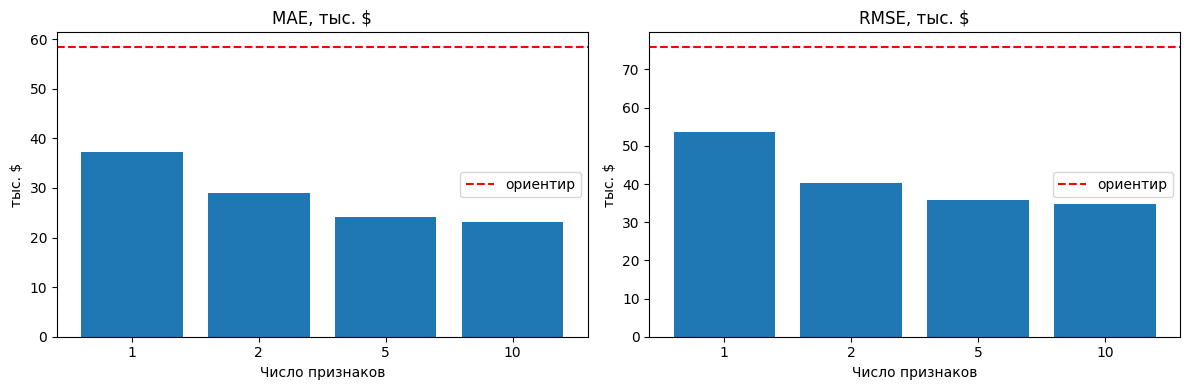

In [32]:
# Напишите решение здесь.
models = {}
imputers = {}
predictions_by_size = {}
rows = []

for size in [1, 2, 5, 10]:
    cols = features_ten[:size]

    imp = SimpleImputer(strategy='mean')
    X_train = imp.fit_transform(train_data[cols])
    X_valid = imp.transform(valid_data[cols])

    X_train = pd.DataFrame(X_train, columns=cols, index=train_data.index)
    X_valid = pd.DataFrame(X_valid, columns=cols, index=valid_data.index)

    model = LinearRegression()
    model.fit(X_train, y_train)
    pred = model.predict(X_valid)

    imputers[size] = imp
    models[size] = model
    predictions_by_size[size] = pred

    mae = mean_absolute_error(y_valid, pred)
    rmse = np.sqrt(mean_squared_error(y_valid, pred))
    rows.append({'Признаков': size, 'MAE': mae, 'RMSE': rmse})

model_comparison = pd.DataFrame(rows)
print('Ориентир: MAE =', round(mae_baseline, 3), ' RMSE =', round(rmse_baseline, 3))
display(model_comparison)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(model_comparison['Признаков'].astype(str), model_comparison['MAE'])
axes[0].axhline(mae_baseline, color='red', linestyle='--', label='ориентир')
axes[0].set_title('MAE, тыс. $')
axes[0].set_xlabel('Число признаков')
axes[0].set_ylabel('тыс. $')
axes[0].set_ylim(bottom=0)
axes[0].legend()

axes[1].bar(model_comparison['Признаков'].astype(str), model_comparison['RMSE'])
axes[1].axhline(rmse_baseline, color='red', linestyle='--', label='ориентир')
axes[1].set_title('RMSE, тыс. $')
axes[1].set_xlabel('Число признаков')
axes[1].set_ylabel('тыс. $')
axes[1].set_ylim(bottom=0)
axes[1].legend()

plt.tight_layout()
plt.show()

### ❓ ? ВЫВОДЫ

Помогли ли дополнительные признаки? Почему RMSE выше MAE? Доказывает ли опыт, что любой новый столбец обязательно улучшит прогноз?

**Мой ответ:**

Дополнительные признаки помогли: ошибки (MAE и RMSE) уменьшаются по мере роста числа признаков от 1 к 10, и все модели регрессии заметно лучше ориентира «всем одна цена». RMSE выше MAE, потому что квадрат сильнее «наказывает» крупные промахи, а в ценах домов есть дорогие выбросы. Опыт не доказывает, что любой новый столбец улучшит прогноз: признаки могут быть шумными, коррелированными или неинформативными, и тогда качество на отложенных данных может ухудшиться.

## 🏠 Д6. Новая заявка и крупные ошибки

1. Создайте `new_home` с десятью входами. Можно выбрать собственный правдоподобный дом; поясните характеристики словами. Например: площадь 120 м², качество 6, год 2000, подвал 50 м², гараж 30 м², участок 500 м², ванные 2, спальни 3, камины 0, граница 18 м.
2. Для каждого размера 1/2/5/10 выберите нужные поля, примените **сохранённый** imputer и соответствующую модель. Выведите четыре цены в тысячах долларов. Не вызывайте fit на новой строке.
3. Для модели с десятью входами создайте таблицу проверочных номеров, настоящих цен, прогнозов и абсолютных ошибок. Покажите три крупнейших промаха через `sort_values(...,ascending=False).head(3)`.
4. Сформулируйте итог: где проверено качество, как очистка и заполнение способны повлиять на прогноз, какие ограничения есть у новой цены.

Необязательное продолжение: изучите дополнительный блок учительского разбора о перемешивании признаков. Он не нужен для зачёта этого ДЗ и не требует отдельного отчёта.

**Что делает следующая ячейка.** Ваш код применяет готовые правила к новому дому, а крупные ошибки ищет только там, где настоящие цены известны. Подстановка новой заявки не даёт собственной оценки качества.

In [35]:
# Напишите решение здесь.
# Новый дом: площадь 120 м², качество 6, год 2000, подвал 50 м²,
# гараж 30 м², участок 500 м², ванные 2, спальни 3, камины 0, граница 18 м
new_home = pd.DataFrame([{
    'Площадь': 120.0,
    'Качество': 6,
    'Год постройки': 2000,
    'Подвал': 50.0,
    'Гараж': 30.0,
    'Участок': 500.0,
    'Ванные': 2,
    'Спальни': 3,
    'Камины': 0,
    'Граница': 18.0,
}])

print('Прогноз цены для нового дома (тыс. $):')
for size in [1, 2, 5, 10]:
    cols = features_ten[:size]
    # Получаем массив из imputer
    X_new_array = imputers[size].transform(new_home[cols])

    # Оборачиваем обратно в DataFrame с названиями колонок, чтобы избежать предупреждений
    X_new_df = pd.DataFrame(X_new_array, columns=cols, index=new_home.index)

    # Теперь predict вызовется без ошибок и предупреждений
    price = models[size].predict(X_new_df)[0]
    print(f'{size:>2} признаков: {price:.2f}')
# Крупнейшие ошибки модели с 10 признаками
pred10 = predictions_by_size[10]
err = pd.DataFrame({
    'Номер': valid_data['Номер'].values,
    'Настоящая цена': y_valid.values,
    'Прогноз': pred10,
    'Абсолютная ошибка': np.abs(y_valid.values - pred10)
})
print('Три крупнейших промаха:')
display(err.sort_values('Абсолютная ошибка', ascending=False).head(3))

Прогноз цены для нового дома (тыс. $):
 1 признаков: 158.02
 2 признаков: 165.04
 5 признаков: 154.12
10 признаков: 147.95
Три крупнейших промаха:


,Номер,Настоящая цена,Прогноз,Абсолютная ошибка
438,2181,183.850,658.845168,474.995168
323,2331,545.224,392.065472,153.158528
180,1783,147.000,295.574042,148.574042


### ❓ ? ВЫВОДЫ

Где у нас есть настоящие ответы для проверки, а где только предположение? Почему хорошее среднее качество не обещает маленький промах для любого дома?

**Мой ответ:**

Настоящие ответы для проверки есть только в valid_data: именно там мы сравниваем прогнозы с реальными ценами. Для нового дома у нас нет настоящей цены — четыре выведенные величины это предположение модели, а не проверенный факт. Хорошее среднее качество (MAE порядка нескольких десятков тысяч долларов) не гарантирует маленький промах для конкретного дома: модель не видит ремонт, расположение, вид из окна, состояние и другие важные факторы; кроме того, линейная регрессия плохо ловит нелинейности и выбросы, а заполнение пропусков средними значениями тоже вносит искажение.